In [2]:
import pandas as pd

In [3]:
train = pd.read_csv("train.csv")

In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_screen   2000

In [5]:
train.describe(include="all")

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [6]:
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [7]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

#### Contoh mengisi nilai yang hilang dengan median untuk kolom numerik

In [8]:

numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

#### Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori

In [9]:

kategorical_features = train[less].select_dtypes(include=['object','string']).columns

for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

#### Menghapus kolom dengan terlalu banyak nilai yang hilang

In [10]:

df = train.drop(columns=over)

In [11]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Hype GLK\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


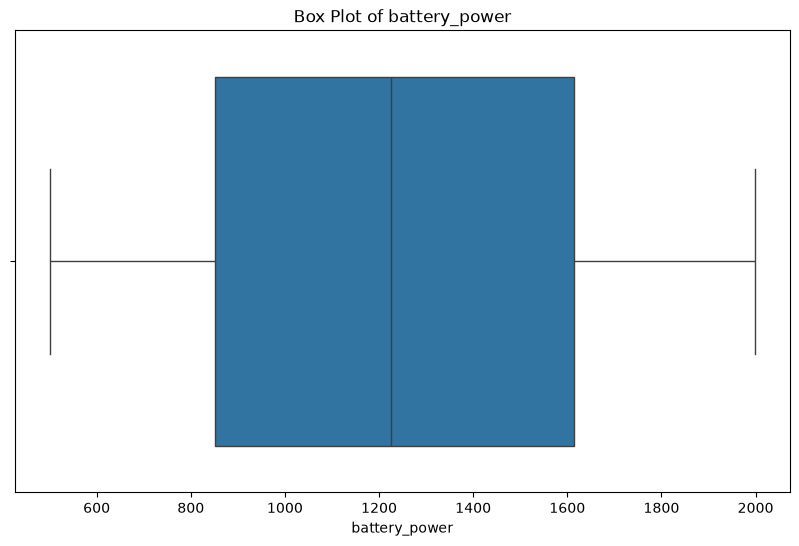

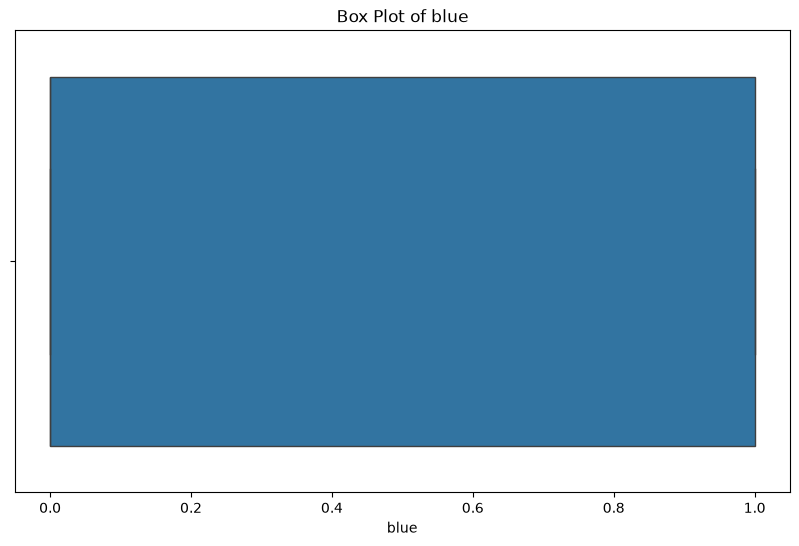

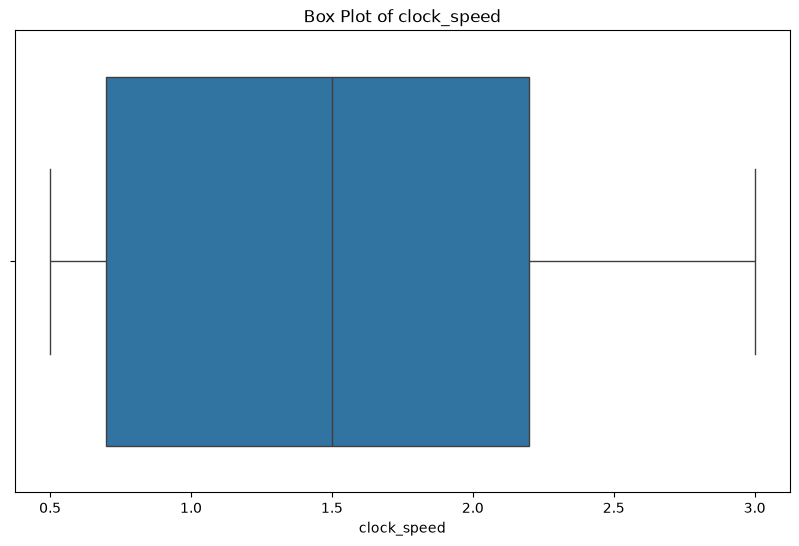

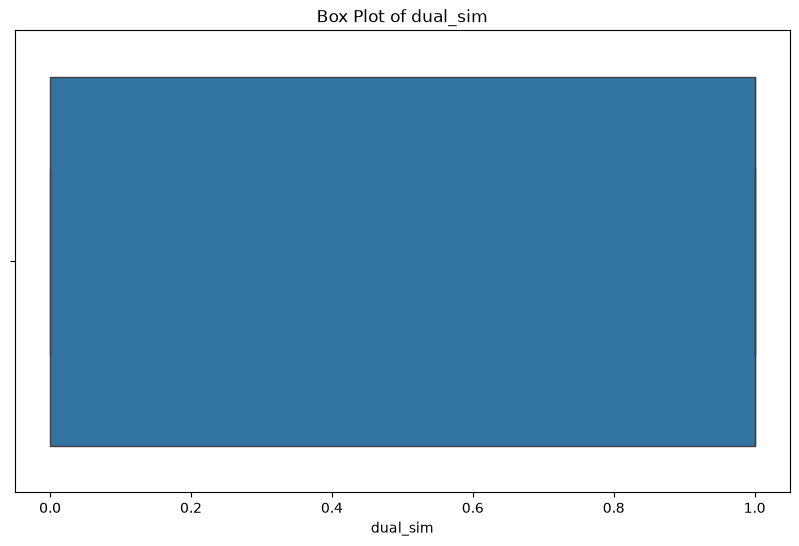

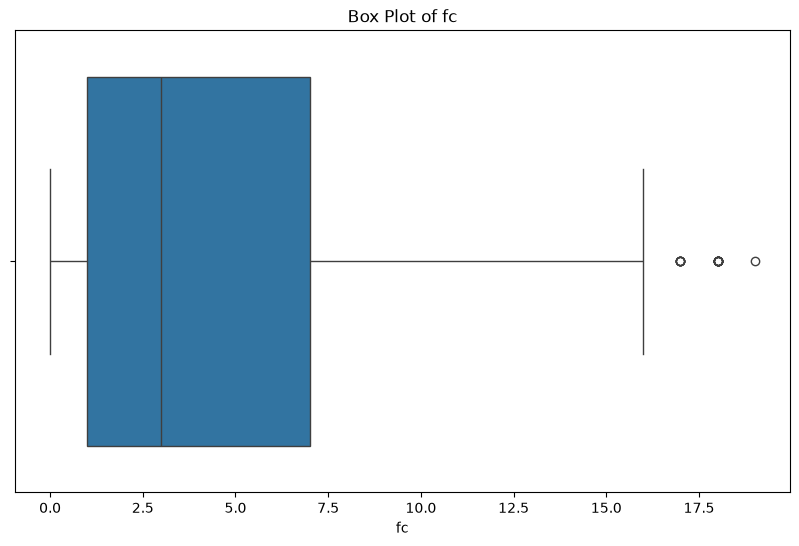

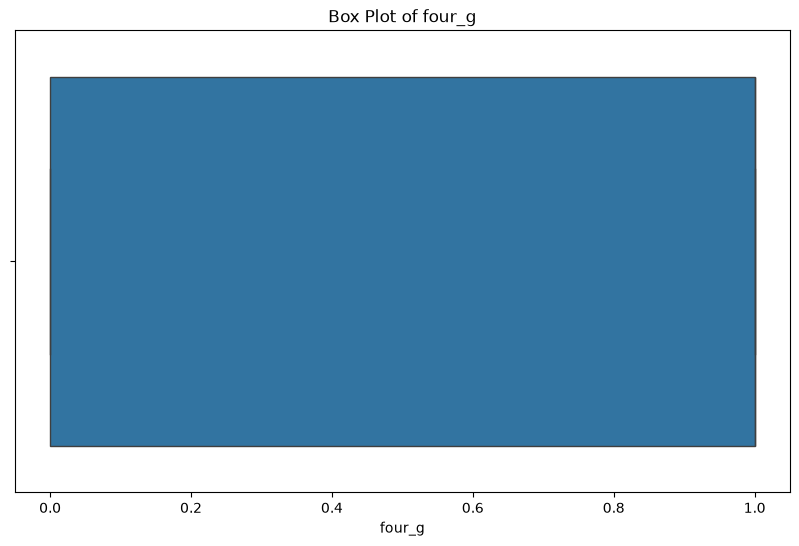

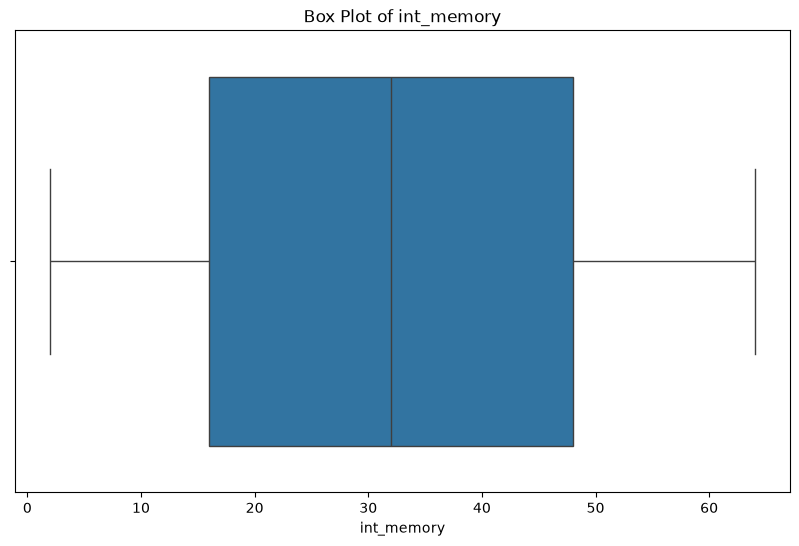

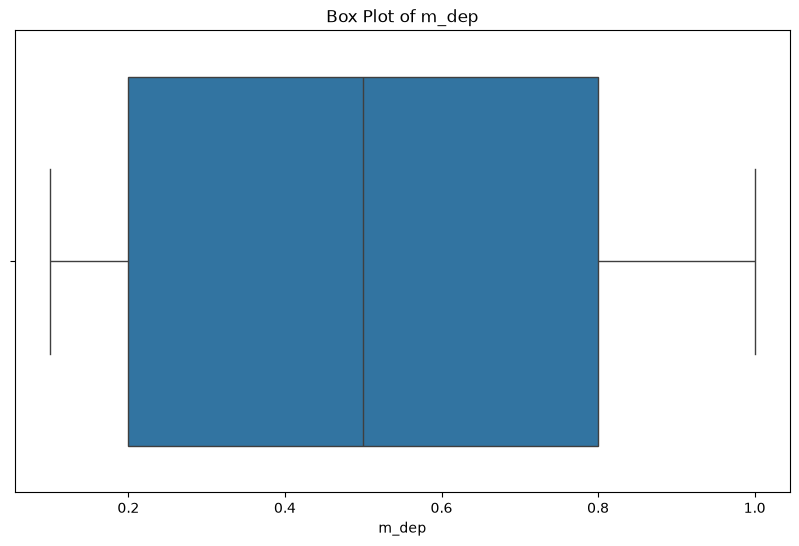

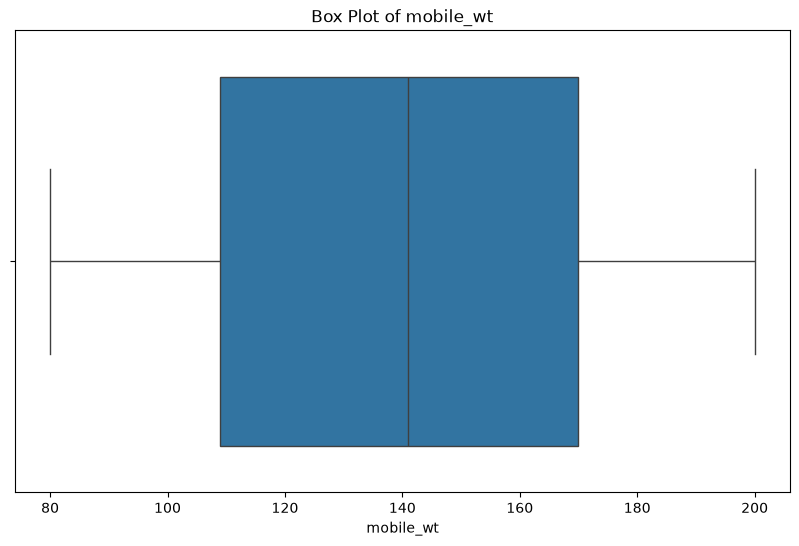

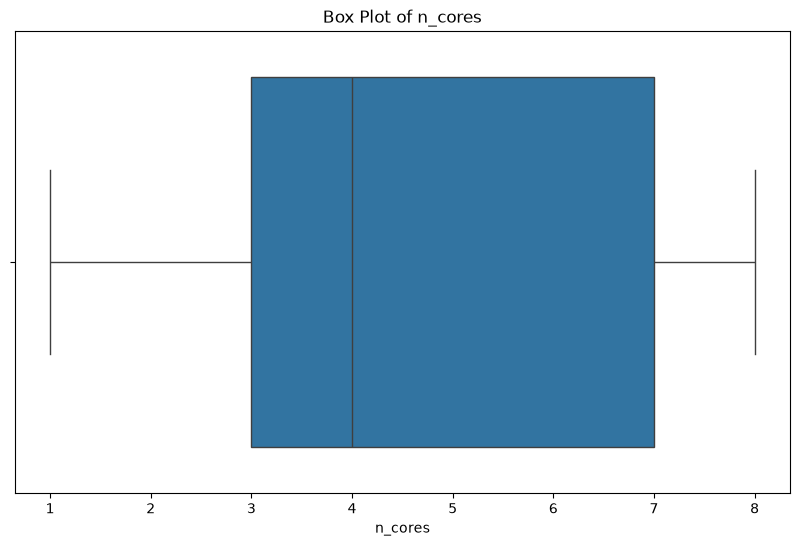

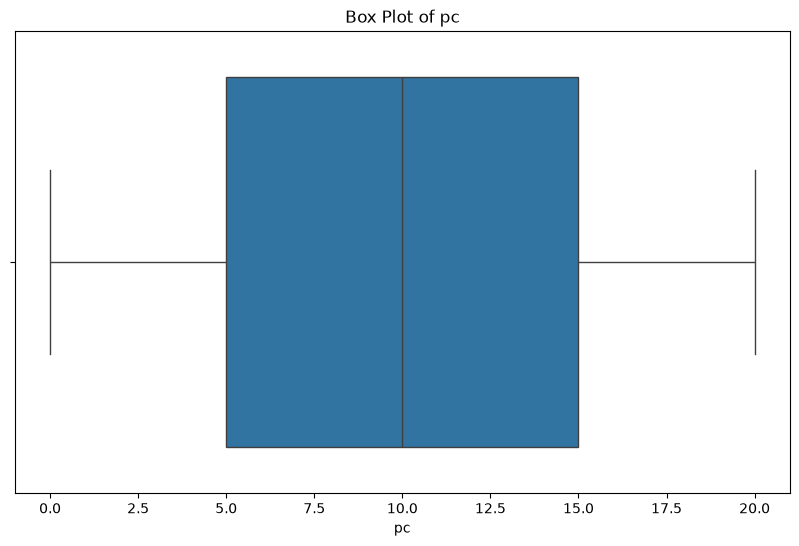

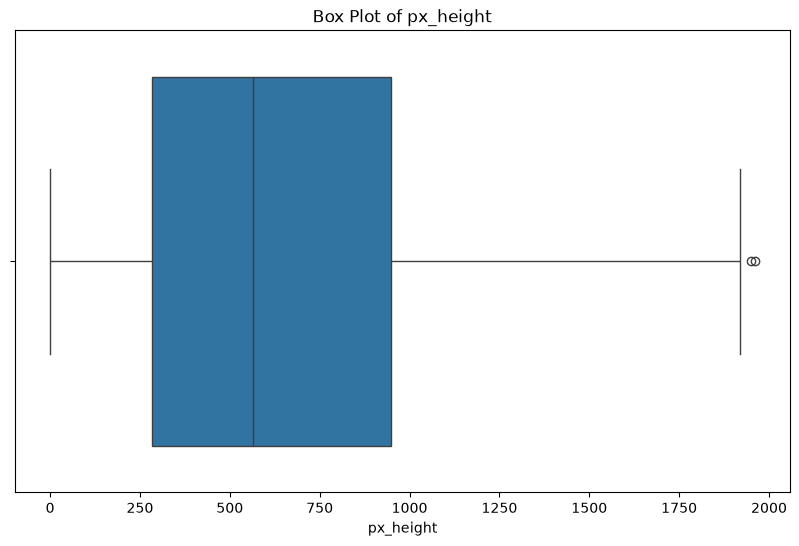

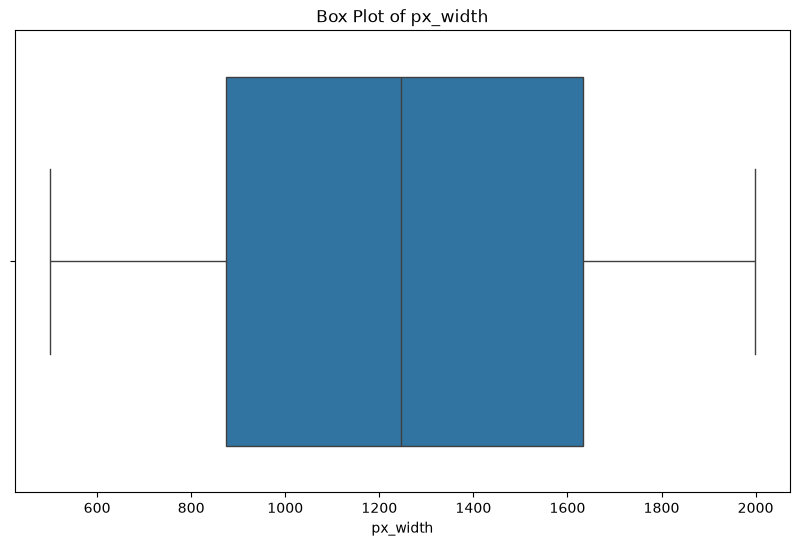

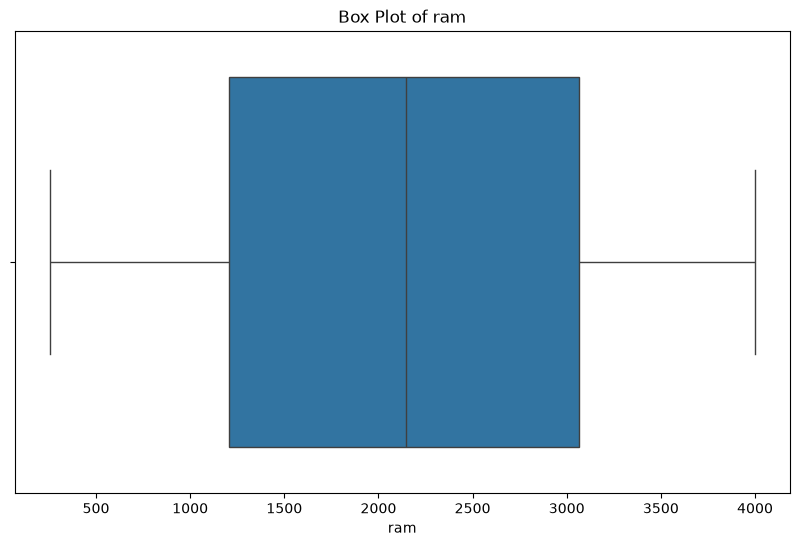

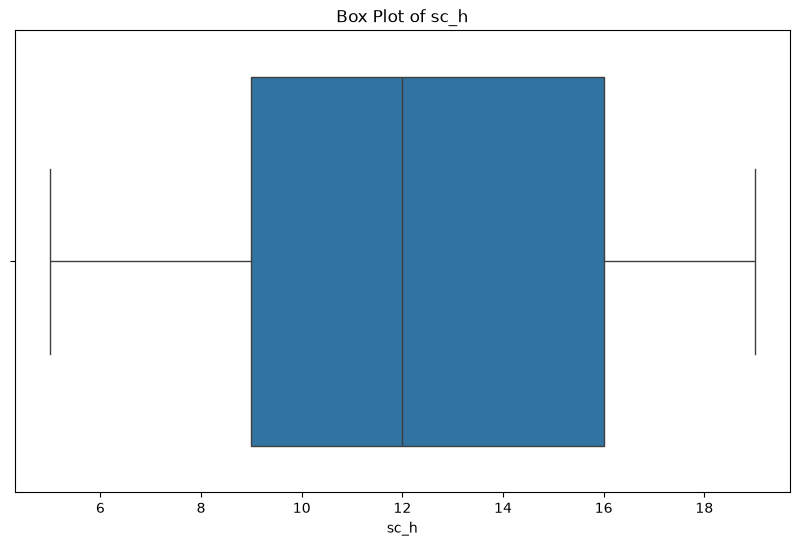

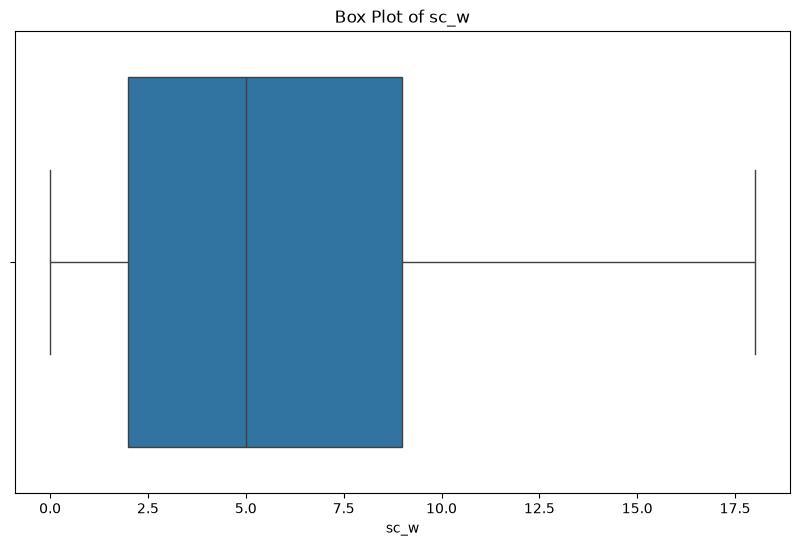

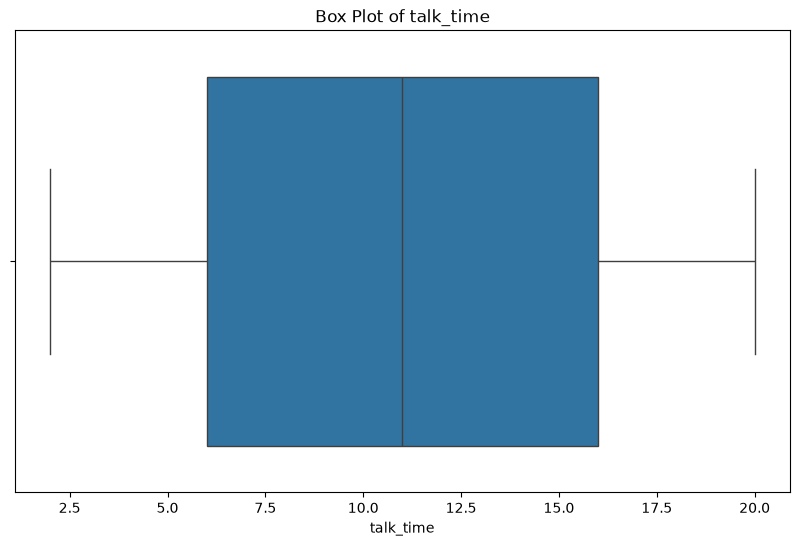

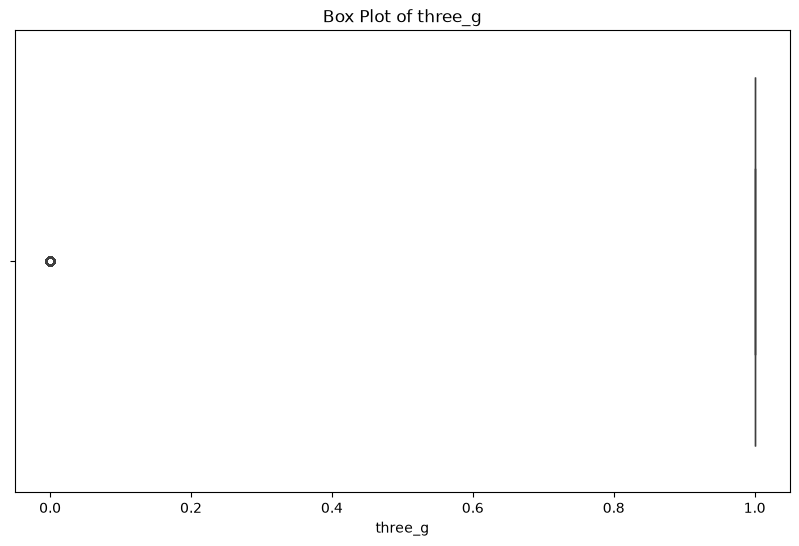

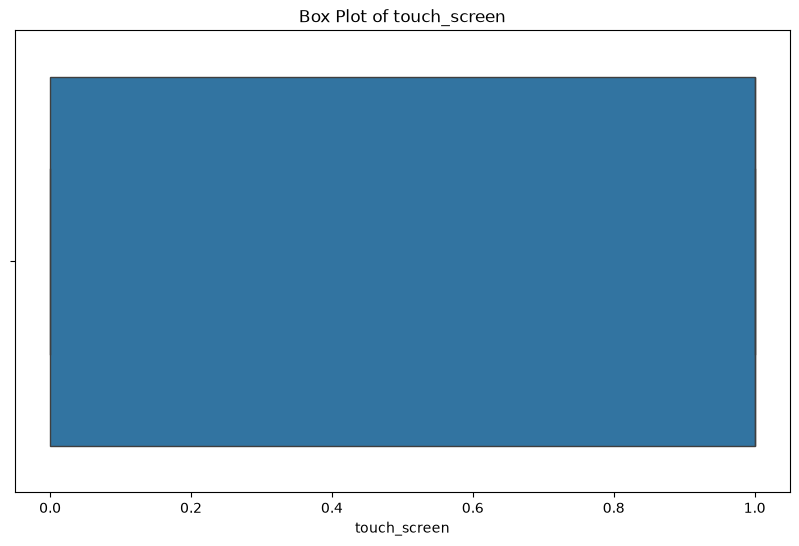

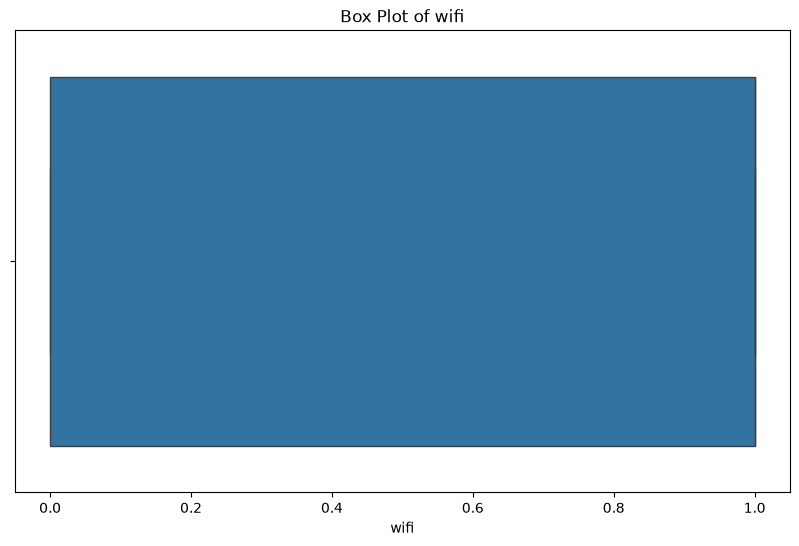

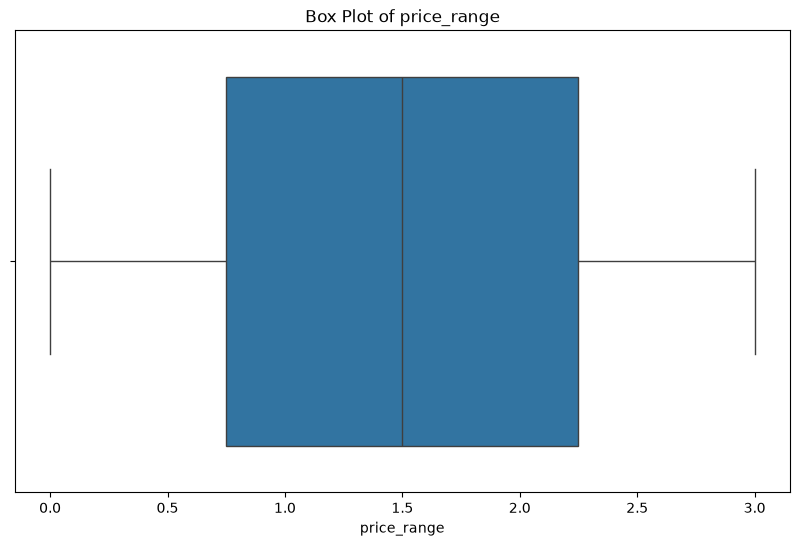

In [12]:
!pip install seaborn

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

#### Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR

In [13]:

Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

#### Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik

#### Menggabungkan kembali dengan kolom kategorikal

In [14]:

condition = ~((df[numeric_features] < (Q1 - 1.5 *IQR)) | (df[numeric_features] > (Q3 + 1.5* IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]


categorical_features = df.select_dtypes(include=['object','string']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

#### Standardisasi fitur numerik

In [15]:
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

#### Histogram Sebelum Standardisasi

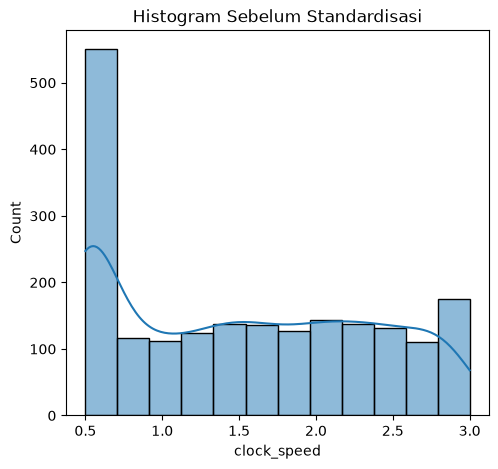

In [16]:

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[2]], kde=True)
plt.title("Histogram Sebelum Standardisasi")
plt.show()

#### Histogram Setelah Standardisasi

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

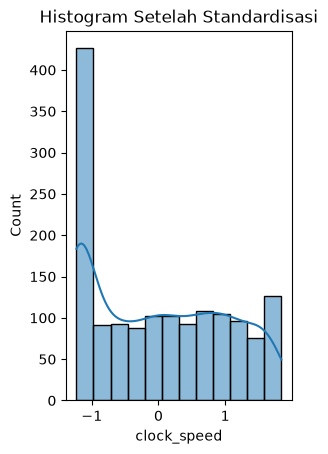

In [17]:

plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[2]], kde=True)
plt.title("Histogram Setelah Standardisasi")

#### Mengidentifikasi baris duplikat

In [18]:

duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [battery_power, blue, clock_speed, dual_sim, fc, four_g, int_memory, m_dep, mobile_wt, n_cores, pc, px_height, px_width, ram, sc_h, sc_w, talk_time, three_g, touch_screen, wifi, price_range]
Index: []

[0 rows x 21 columns]


#### Menghapus baris duplikat

In [19]:

df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
      battery_power      blue  clock_speed  dual_sim        fc    four_g  \
1         -0.496650  1.028288    -1.230115  0.989432 -0.992446  0.678762   
2         -1.539913  1.028288    -1.230115  0.989432 -0.517887  0.678762   
3         -1.421464  1.028288     1.228157 -1.010681 -0.992446 -1.473271   
4          1.325646  1.028288    -0.369720 -1.010681  2.092189  0.678762   
5          1.412205 -0.972490    -1.230115  0.989432 -0.280608 -1.473271   
...             ...       ...          ...       ...       ...       ...   
1995      -1.013726  1.028288    -1.230115  0.989432 -0.992446  0.678762   
1996       1.653659  1.028288     1.351070  0.989432 -0.992446 -1.473271   
1997       1.530654 -0.972490    -0.738461  0.989432 -0.755167  0.678762   
1998       0.621784 -0.972490    -0.738461 -1.010681 -0.043328  0.678762   
1999      -1.660641  1.028288     0.613589  0.989432  0.193952  0.678762   

      int_memory     m_dep  mobile_wt   n_cores  

In [20]:
category_features = df.select_dtypes(include=['object','string']).columns
df[category_features]

""
1
2
3
4
5
...
1995
1996
1997
1998


In [21]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
1,-0.496650,1.028288,-1.230115,0.989432,-0.992446,0.678762,1.155434,0.695039,-0.119621,-0.662592,...,0.625802,1.722560,0.456555,1.105218,-0.645011,-0.712037,0.0,0.988118,-1.010681,0.435702
2,-1.539913,1.028288,-1.230115,0.989432,-0.517887,0.678762,0.496540,1.390078,0.136556,0.216196,...,1.448534,1.088277,0.430729,-0.319222,-0.871441,-0.343856,0.0,0.988118,-1.010681,0.435702
3,-1.421464,1.028288,1.228157,-1.010681,-0.992446,-1.473271,-1.205602,1.042559,-0.261942,0.655590,...,1.340522,1.251511,0.583838,0.867812,0.487141,0.024325,0.0,-1.012024,-1.010681,0.435702
4,1.325646,1.028288,-0.369720,-1.010681,2.092189,0.678762,0.661264,0.347520,0.022699,-1.101986,...,1.322137,-0.087012,-0.668705,-1.031443,-0.871441,0.760688,0.0,0.988118,-1.010681,-0.460702
5,1.412205,-0.972490,-1.230115,0.989432,-0.280608,-1.473271,-0.546708,0.695039,0.677375,-1.541379,...,0.853317,0.943698,-0.985991,1.105218,-1.097872,-0.159765,0.0,-1.012024,-1.010681,-0.460702
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,-1.013726,1.028288,-1.230115,0.989432,-0.992446,0.678762,-1.644865,1.042559,-0.973546,0.655590,...,1.354311,1.494031,-1.354006,0.155591,-0.418581,1.497051,0.0,0.988118,-1.010681,-1.357105
1996,1.653659,1.028288,1.351070,0.989432,-0.992446,-1.473271,0.386725,-1.042559,1.332050,-0.223198,...,0.648784,1.668925,-0.095929,-0.319222,0.940002,0.944779,0.0,0.988118,0.989432,0.435702
1997,1.530654,-0.972490,-0.738461,0.989432,-0.755167,0.678762,0.222001,0.695039,-0.916617,1.534377,...,0.540771,0.892395,0.849473,-0.794036,-1.097872,-1.080219,0.0,0.988118,-1.010681,1.332106
1998,0.621784,-0.972490,-0.738461,-1.010681,-0.043328,0.678762,0.771079,-1.390078,0.136556,0.216196,...,-0.681836,-1.350914,-1.168615,1.342625,0.940002,1.497051,0.0,0.988118,0.989432,-1.357105


#### Inisialisasi LabelEncoder

#### Menampilkan hasil

In [22]:
from sklearn.preprocessing import LabelEncoder


label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])


df_lencoder

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
1,-0.496650,1.028288,-1.230115,0.989432,-0.992446,0.678762,1.155434,0.695039,-0.119621,-0.662592,...,0.625802,1.722560,0.456555,1.105218,-0.645011,-0.712037,0.0,0.988118,-1.010681,0.435702
2,-1.539913,1.028288,-1.230115,0.989432,-0.517887,0.678762,0.496540,1.390078,0.136556,0.216196,...,1.448534,1.088277,0.430729,-0.319222,-0.871441,-0.343856,0.0,0.988118,-1.010681,0.435702
3,-1.421464,1.028288,1.228157,-1.010681,-0.992446,-1.473271,-1.205602,1.042559,-0.261942,0.655590,...,1.340522,1.251511,0.583838,0.867812,0.487141,0.024325,0.0,-1.012024,-1.010681,0.435702
4,1.325646,1.028288,-0.369720,-1.010681,2.092189,0.678762,0.661264,0.347520,0.022699,-1.101986,...,1.322137,-0.087012,-0.668705,-1.031443,-0.871441,0.760688,0.0,0.988118,-1.010681,-0.460702
5,1.412205,-0.972490,-1.230115,0.989432,-0.280608,-1.473271,-0.546708,0.695039,0.677375,-1.541379,...,0.853317,0.943698,-0.985991,1.105218,-1.097872,-0.159765,0.0,-1.012024,-1.010681,-0.460702
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,-1.013726,1.028288,-1.230115,0.989432,-0.992446,0.678762,-1.644865,1.042559,-0.973546,0.655590,...,1.354311,1.494031,-1.354006,0.155591,-0.418581,1.497051,0.0,0.988118,-1.010681,-1.357105
1996,1.653659,1.028288,1.351070,0.989432,-0.992446,-1.473271,0.386725,-1.042559,1.332050,-0.223198,...,0.648784,1.668925,-0.095929,-0.319222,0.940002,0.944779,0.0,0.988118,0.989432,0.435702
1997,1.530654,-0.972490,-0.738461,0.989432,-0.755167,0.678762,0.222001,0.695039,-0.916617,1.534377,...,0.540771,0.892395,0.849473,-0.794036,-1.097872,-1.080219,0.0,0.988118,-1.010681,1.332106
1998,0.621784,-0.972490,-0.738461,-1.010681,-0.043328,0.678762,0.771079,-1.390078,0.136556,0.216196,...,-0.681836,-1.350914,-1.168615,1.342625,0.940002,1.497051,0.0,0.988118,0.989432,-1.357105


In [23]:
df_lencoder.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
1,-0.496650,1.028288,-1.230115,0.989432,-0.992446,0.678762,1.155434,0.695039,-0.119621,-0.662592,...,0.625802,1.722560,0.456555,1.105218,-0.645011,-0.712037,0.0,0.988118,-1.010681,0.435702
2,-1.539913,1.028288,-1.230115,0.989432,-0.517887,0.678762,0.496540,1.390078,0.136556,0.216196,...,1.448534,1.088277,0.430729,-0.319222,-0.871441,-0.343856,0.0,0.988118,-1.010681,0.435702
3,-1.421464,1.028288,1.228157,-1.010681,-0.992446,-1.473271,-1.205602,1.042559,-0.261942,0.655590,...,1.340522,1.251511,0.583838,0.867812,0.487141,0.024325,0.0,-1.012024,-1.010681,0.435702
4,1.325646,1.028288,-0.369720,-1.010681,2.092189,0.678762,0.661264,0.347520,0.022699,-1.101986,...,1.322137,-0.087012,-0.668705,-1.031443,-0.871441,0.760688,0.0,0.988118,-1.010681,-0.460702
5,1.412205,-0.972490,-1.230115,0.989432,-0.280608,-1.473271,-0.546708,0.695039,0.677375,-1.541379,...,0.853317,0.943698,-0.985991,1.105218,-1.097872,-0.159765,0.0,-1.012024,-1.010681,-0.460702


#### Menghitung jumlah dan persentase missing values di setiap kolom

#### Menampilkan kolom dengan missing values

In [24]:

missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100
 
missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)
 S
missing_data[missing_data['Missing Values'] > 0] 

IndentationError: unexpected indent (2838941623.py, line 8)

#### Menghitung jumlah variabel

#### Menentukan jumlah baris dan kolom untuk grid subplot
#### Jumlah kolom yang diinginkan
#### Ceiling division untuk menentukan jumlah baris


#### Membuat subplot

#### Flatten axes array untuk memudahkan iterasi jika diperlukan

#### Plot setiap variabel

#### Menghapus subplot yang tidak terpakai (jika ada)

#### Menyesuaikan layout agar lebih rapi

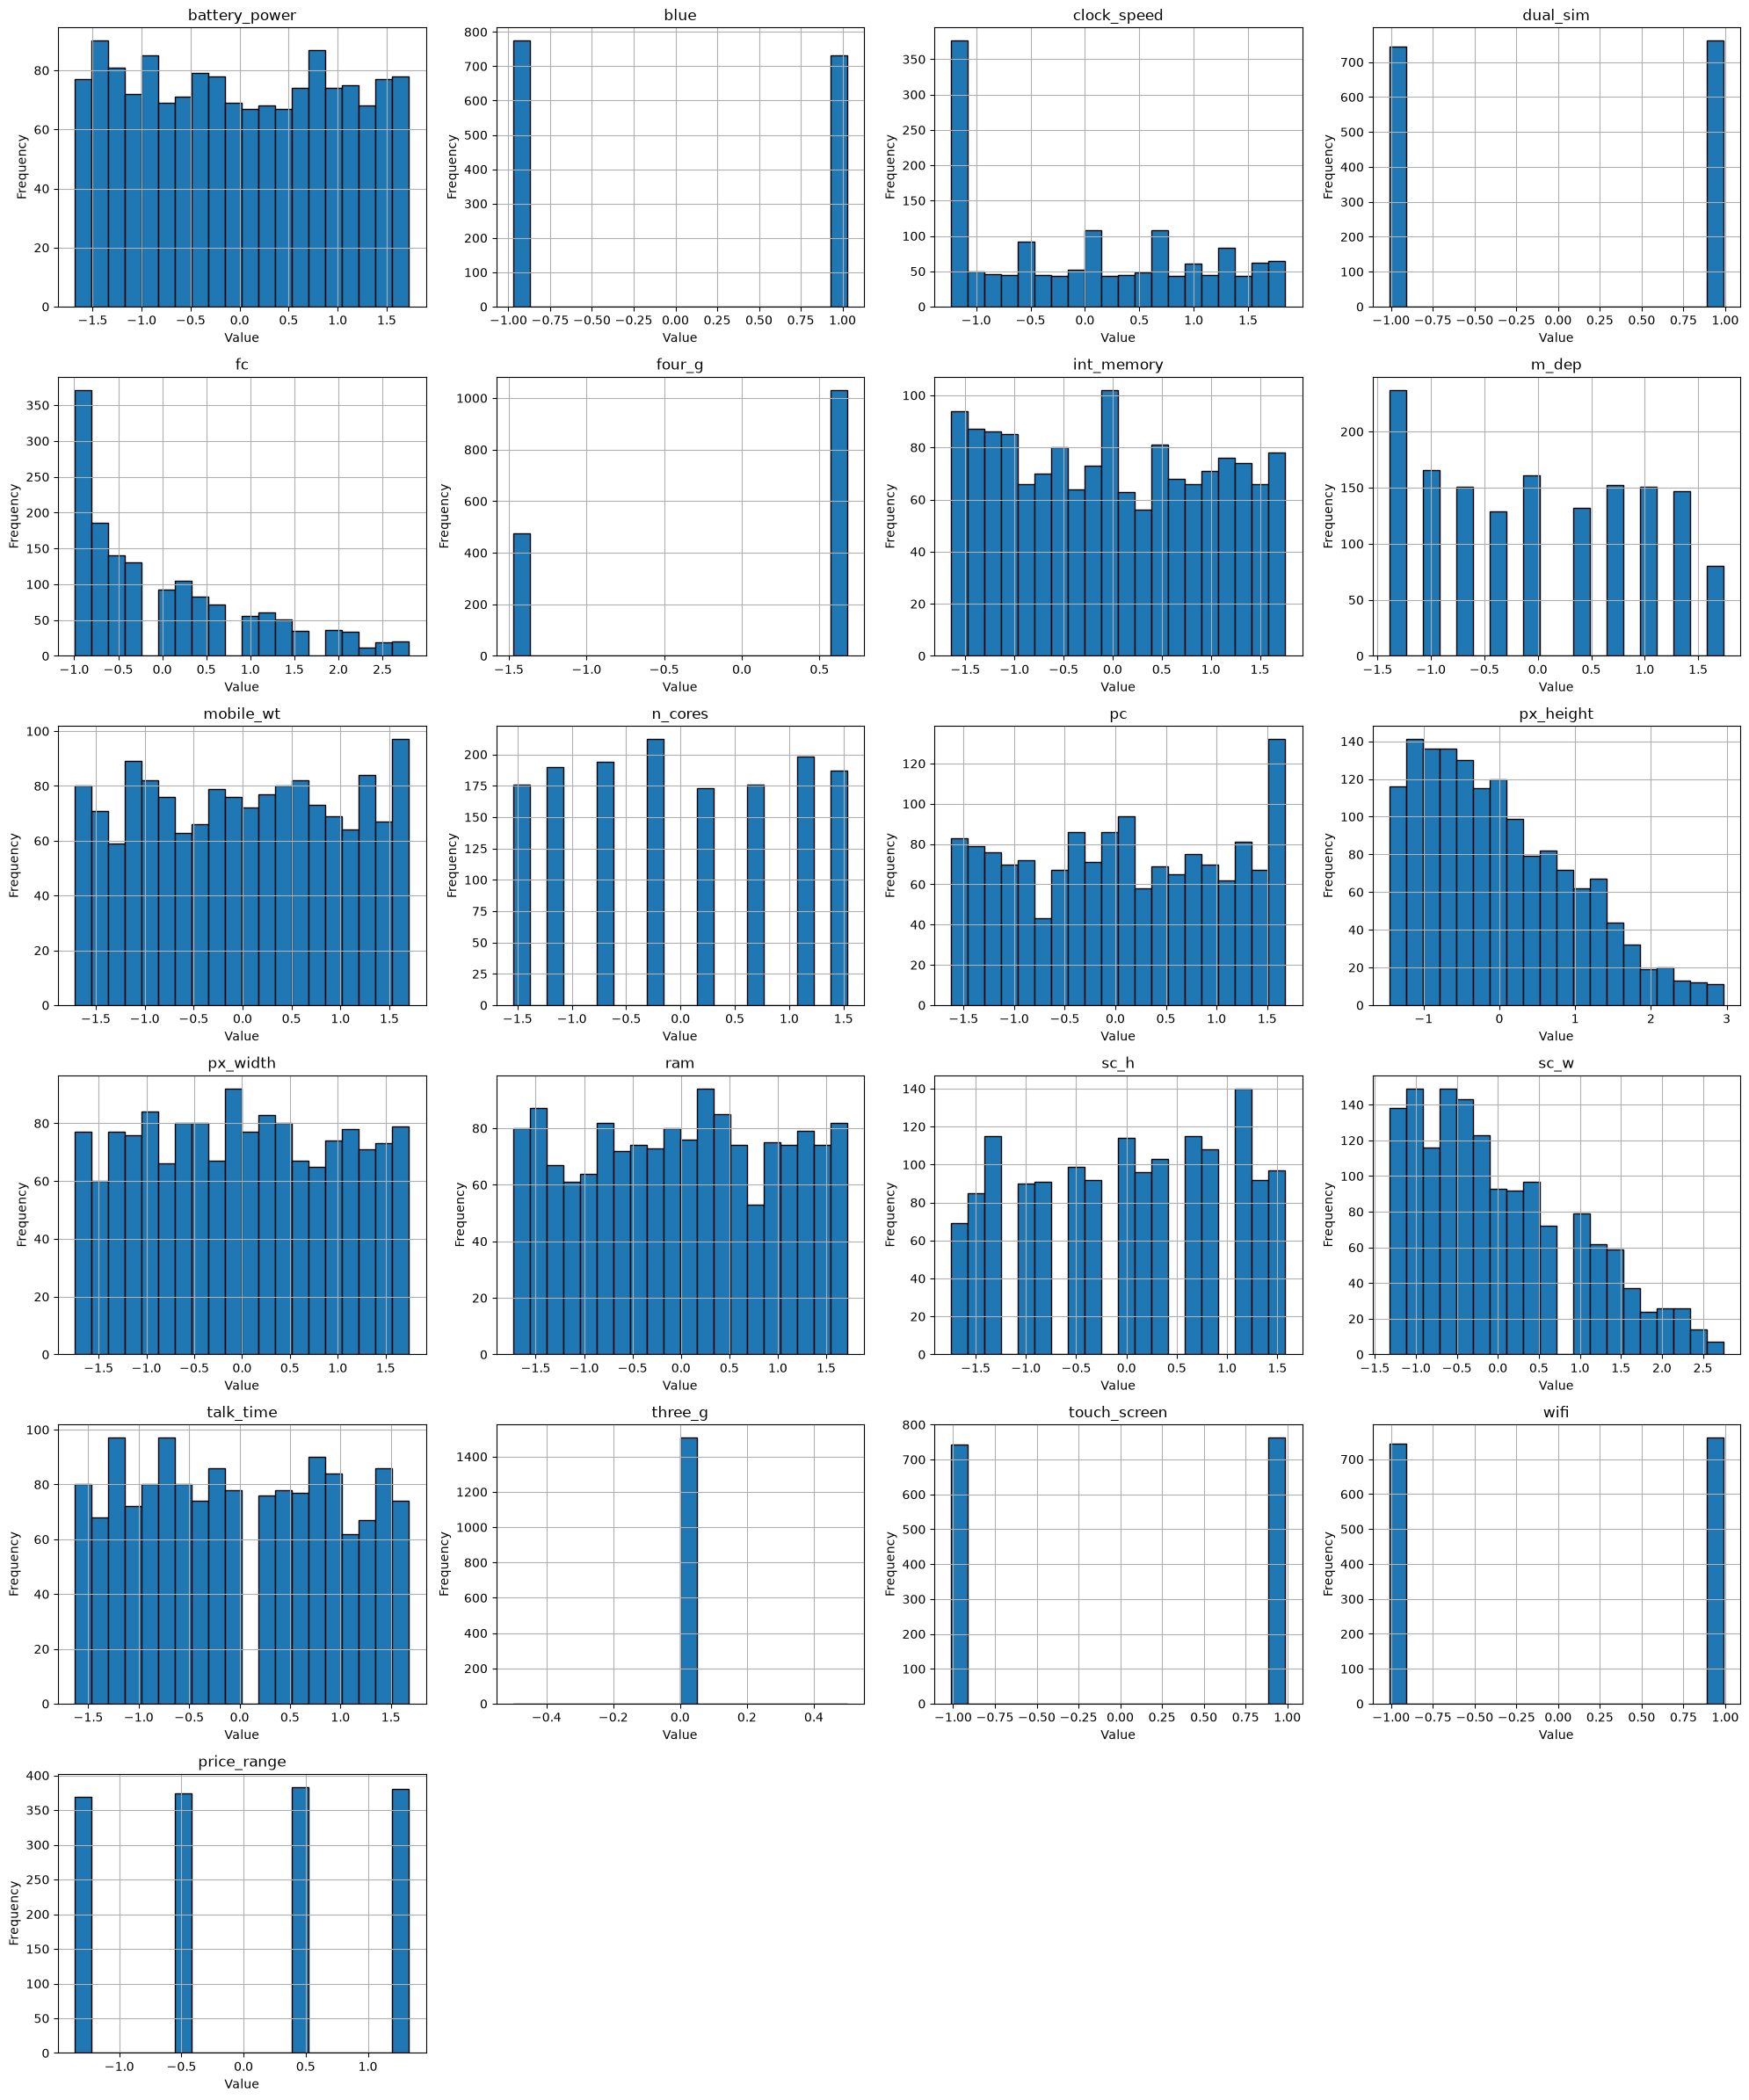

In [ ]:

num_vars = df_lencoder.shape[1]


n_cols = 4 
n_rows = -(-num_vars // n_cols) 


fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))


axes = axes.flatten()


for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])


plt.tight_layout()
plt.show()


#### Visualisasi distribusi data untuk beberapa kolom

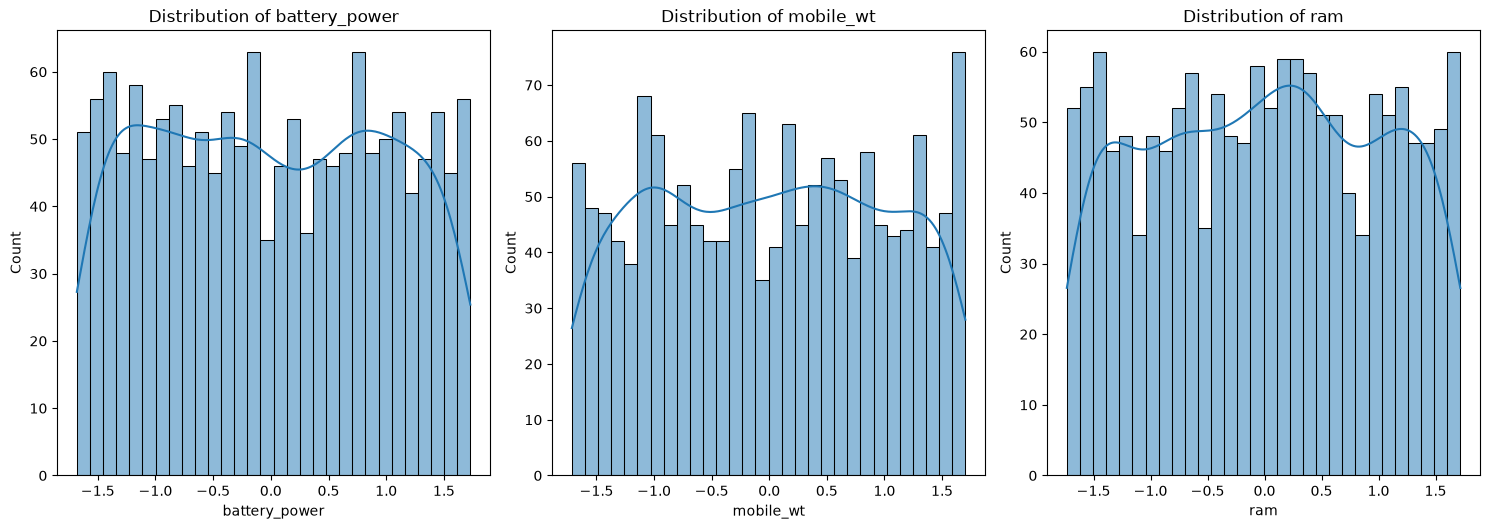

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


columns_to_plot = ['battery_power', 'mobile_wt', 'ram']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

#### Visualisasi korelasi antar variabel numerik

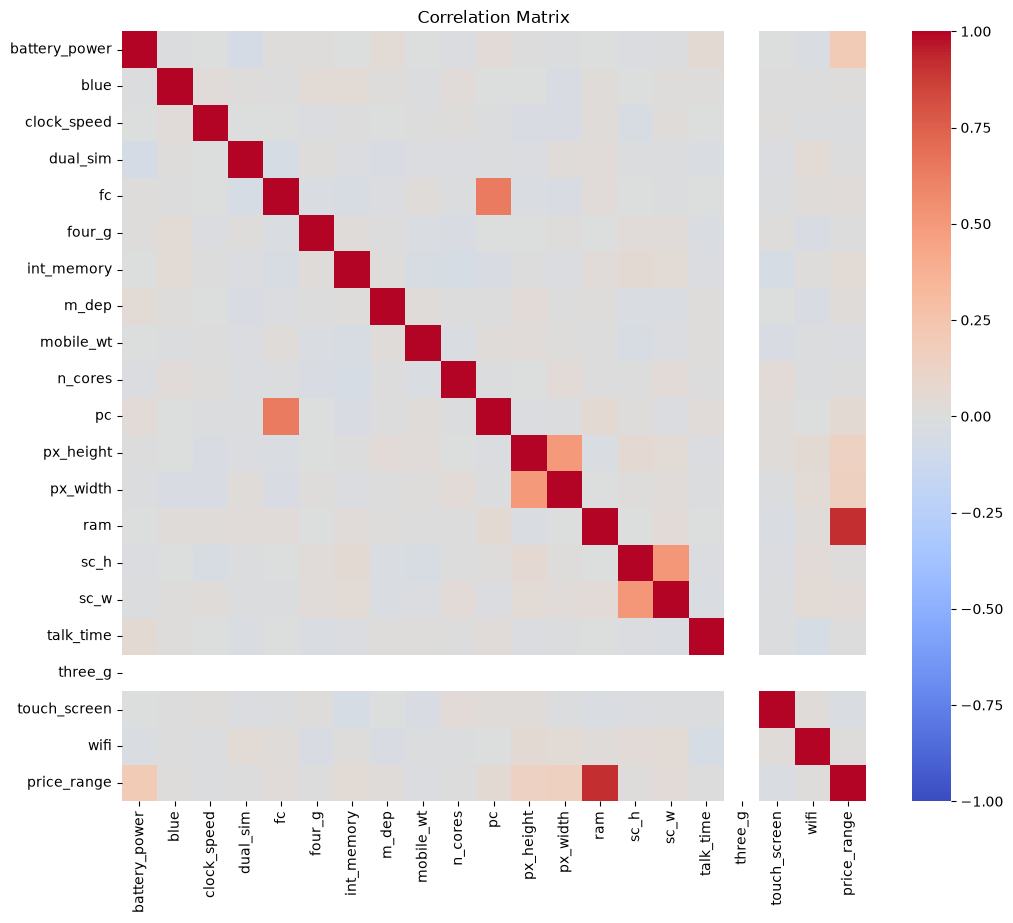

In [ ]:

plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

#### Menghitung korelasi antara variabel target dan semua variabel lainnya

#### (Opsional) Mengurutkan hasil korelasi berdasarkan korelasi

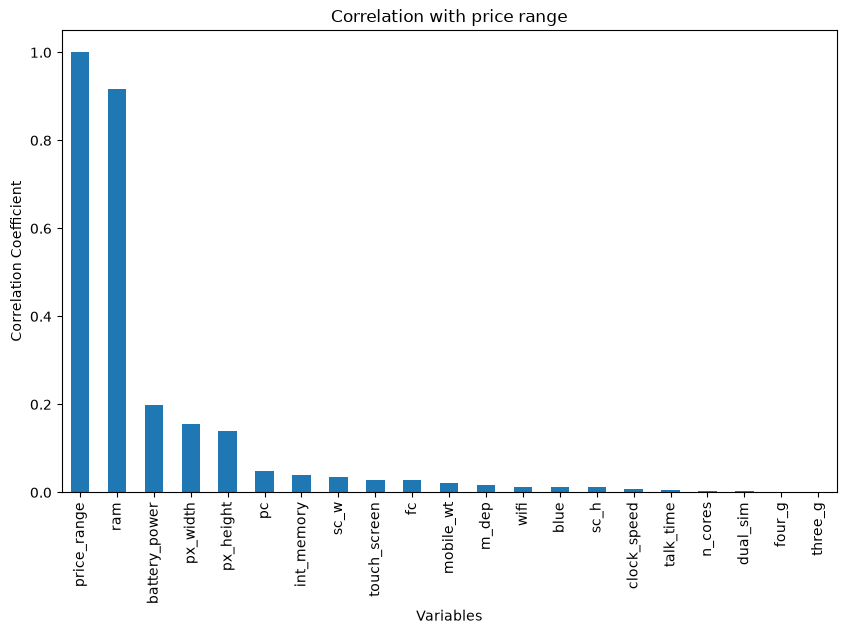

In [ ]:

target_corr = df_lencoder.corr()['price_range']


target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title(f'Correlation with price range')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

In [ ]:
import sklearn

#### Memisahkan fitur (X) dan target (y)

In [ ]:

X = df_lencoder.drop(columns=['price_range'])
y = df_lencoder['price_range']

#### membagi dataset menjadi training dan testing 

In [ ]:
from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

#### menghitung panjang/jumlah data 

#### menghitung panjang/jumlah data pada x_train

#### menghitung panjang/jumlah data pada x_test

In [ ]:

print("Jumlah data: ",len(X))

print("Jumlah data latih: ",len(x_train))

print("Jumlah data test: ",len(x_test))

Jumlah data:  1506
Jumlah data latih:  1204
Jumlah data test:  302


#### Memisahkan fitur (X) dan target (y)

In [ ]:


X = df_lencoder.drop(columns=['price_range'])
y = df_lencoder['price_range']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1
)

In [ ]:
print("Jumlah data:", len(X))
print("Jumlah data latih:", len(X_train))
print("Jumlah data test:", len(X_test))

Jumlah data: 1506
Jumlah data latih: 1204
Jumlah data test: 302


#### Melatih model 1 dengan algoritma Least Angle Regression

#### Melatih model 2 dengan algoritma Linear Regression

#### Melatih model 3 dengan algoritma Gradient Boosting Regressor

In [ ]:

from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(X_train, y_train)


from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(X_train, y_train)


from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",184
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, in

#### Evaluasi pada model LARS

#### Membuat dictionary untuk menyimpan hasil evaluasi

#### Konversi dictionary menjadi DataFrame

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)


data = {
 'MAE': [mae_lars],
 'MSE': [mse_lars],
 'R2': [r2_lars]
 }


df_results = pd.DataFrame(data, index=['Lars'])
df_results



,MAE,MSE,R2
Lars,0.362303,0.200977,0.782466


#### Evaluasi pada model Linear Regression

#### Menambahkan hasil evaluasi LR ke DataFrame

In [ ]:

pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)


df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results


,MAE,MSE,R2
Lars,0.362303,0.200977,0.782466
Linear Regression,0.236291,0.080745,0.912603


#### Evaluasi pada model Gradient Boosting Regressor

#### Menambahkan hasil evaluasi GBR ke DataFrame

In [ ]:

pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)


df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,0.362303,0.200977,0.782466
Linear Regression,0.236291,0.080745,0.912603
GradientBoostingRegressor,0.208996,0.069491,0.924784


#### Menyimpan model ke dalam file

#### joblib.dump(GBR, 'gbr_model.joblib')

In [ ]:
import joblib



#### Menyimpan model ke dalam file

In [ ]:
import pickle


with open('gbr_model.pkl', 'wb') as file:
    pickle.dump(GBR, file)


#### 1. Memuat Dataset (pastikan nama file sesuai, misal 'train.csv')

#### 2. Menentukan Fitur (X) dan Target (y) menggunakan 'price_range'

#### Mengisi missing values jika ada

#### Membagi data latih dan uji

#### 3. Melatih Model Gradient Boosting Regressor

#### 4. Menyimpan Model ke file joblib dan pickle

#### 5. MEMUAT KEMBALI MODEL

#### Memuat model dari file joblib

#### A. Memuat model dari file pickle

#### B. Memuat model dari file pickle

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
import joblib
import pickle


df = pd.read_csv('train.csv')


X = df.drop(columns=['price_range']) 
y = df['price_range']


X = X.fillna(X.median(numeric_only=True))


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


gbr_model = GradientBoostingRegressor(random_state=42)
gbr_model.fit(X_train, y_train)


joblib.dump(gbr_model, 'gbr_model.joblib')
with open('gbr_model.pkl', 'wb') as file:
    pickle.dump(gbr_model, file)

print("Model berhasil dilatih dan disimpan!")



joblib_model = joblib.load('gbr_model.joblib')


with open('gbr_model.pkl', 'rb') as file:
    pickle_model = pickle.load(file)

print("Model berhasil dimuat kembali!")

Model berhasil dilatih dan disimpan!
Model berhasil dimuat kembali!
